In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [6]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

# Single Run

In [3]:

algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=int(50), strategy1='AC', strategy2='AC', verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 50)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

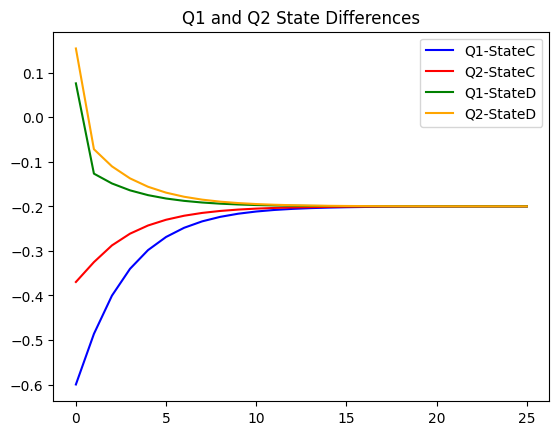

In [4]:
internal_debug = True
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.title('Q1 and Q2 State Differences')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [5]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


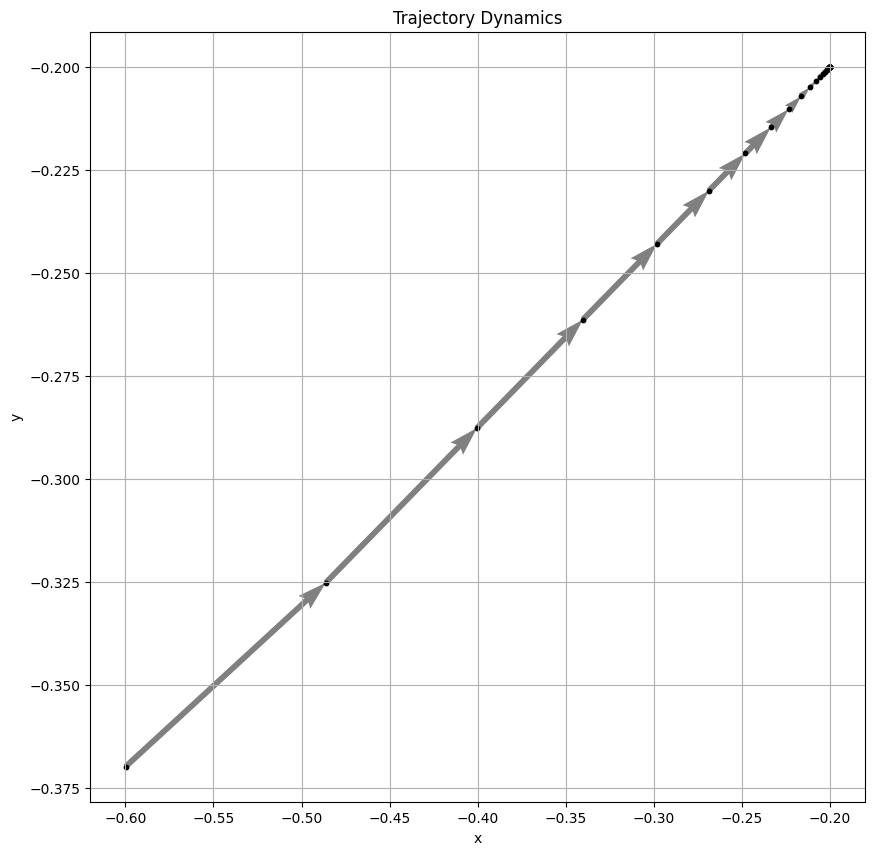

In [6]:
trajectory_dynamics_plot(x, y)

# SYSTEMATIC REVIEW

In [34]:
import numpy as np
import matplotlib.pyplot as plt

class VectorFieldAutomatic:
    """
    Vector field plotter automatico come Mathematica:
    - ΔQ calcolato per ogni punto della meshgrid
    - Gestisce automaticamente uno o più equilibri
    - Due subplots: StateC-StateC e StateD-StateD
    - Traiettorie e BoA incluse
    """

    def __init__(self, q1=None, q2=None,
                 t=1, r=0.8, p=0.2, s=0,
                 epsilon=0.1, d=0.7,
                 func1=None, func2=None,
                 alpha=0.3, density=15,
                 show_trajectory=True, show_basin=True):
        
        self.q1 = q1
        self.q2 = q2
        self.t, self.r, self.p, self.s = t, r, p, s
        self.epsilon = epsilon
        self.delta = d
        self.alpha = alpha
        self.density = density
        self.show_trajectory = show_trajectory
        self.show_basin = show_basin

        self.func1 = func1
        self.func2 = func2

        self.bound = 1 / (1 - self.delta)

        if self.show_trajectory:
            if self.q1 is None or self.q2 is None:
                raise ValueError("q1 and q2 must be provided if show_trajectory is True.")
            self.prepare_states()

        self.compute_boa()

    def prepare_states(self):
        """Calcola StateC e StateD per le traiettorie."""
        self.q1['StateC'] = self.q1['Q3'] - self.q1['Q1']
        self.q1['StateD'] = self.q1['Q4'] - self.q1['Q2']
        self.q2['StateC'] = self.q2['Q3'] - self.q2['Q1']
        self.q2['StateD'] = self.q2['Q4'] - self.q2['Q2']

        self.xC, self.yC = self.q1['StateC'].values, self.q2['StateC'].values
        self.uC, self.vC = self.xC[1:] - self.xC[:-1], self.yC[1:] - self.yC[:-1]

        self.xD, self.yD = self.q1['StateD'].values, self.q2['StateD'].values
        self.uD, self.vD = self.xD[1:] - self.xD[:-1], self.yD[1:] - self.yD[:-1]

    def compute_boa(self):
        """Calcola BoA (basin of attraction) dalle funzioni Q in (0,0)."""
        if self.func1 is None or self.func2 is None:
            self.boa_x = self.boa_y = None
            return

        Q1 = self.func1(self.t, self.r, self.p, self.s, self.epsilon, self.delta)[0]
        Q2 = self.func2(self.t, self.r, self.p, self.s, self.epsilon, self.delta)[0]

        dx = Q1[0] - Q1[1]
        dy = Q2[0] - Q2[1]

        scale = min(1 / ((1 - self.delta) * abs(dx) + 1e-8),
                    1 / ((1 - self.delta) * abs(dy) + 1e-8))
        self.boa_x = np.array([0, -scale * dx])
        self.boa_y = np.array([0, -scale * dy])

    def vector_field(self, X, Y, func):
        """
        Calcola ΔQ per ogni punto (X,Y) usando la funzione Q.
        """
        U = np.zeros_like(X)
        V = np.zeros_like(Y)

        if func is None:
            return U, V

        Q = func(self.t, self.r, self.p, self.s, self.epsilon, self.delta)[0]

        dQx = Q[0] - Q[1]
        dQy = Q[0] - Q[1]

        U = self.alpha * (dQx - X)
        V = self.alpha * (dQy - Y)

        mag = np.sqrt(U**2 + V**2) + 1e-8
        return U / mag, V / mag

    def add_vector_field(self, ax, xmin, xmax, ymin, ymax, func):
        """Aggiunge vettori al plot calcolati punto-per-punto."""
        X_vals = np.linspace(xmin, xmax, self.density)
        Y_vals = np.linspace(ymin, ymax, self.density)
        X, Y = np.meshgrid(X_vals, Y_vals)
        U, V = self.vector_field(X, Y, func)
        ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=12,
                  color='black', alpha=0.7, width=0.003)

    def plot(self):
        """Disegna due subplots: StateC-StateC e StateD-StateD."""
        fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

        for i, (x_attr, y_attr, u_attr, v_attr, state_name, func, color) in enumerate([
            ('xC', 'yC', 'uC', 'vC', 'StateC', self.func1, 'blue'),
            ('xD', 'yD', 'uD', 'vD', 'StateD', self.func2, 'orange')
        ]):
            ax = axes[i]

            # Quadranti come in Mathematica
            bound = self.bound
            quadrants = [
                (0, bound, -bound, 0),
                (-bound, 0, -bound, 0),
                (0, bound, 0, bound),
                (-bound, 0, 0, bound)
            ]
            for xmin, xmax, ymin, ymax in quadrants:
                self.add_vector_field(ax, xmin, xmax, ymin, ymax, func)

            # Traiettoria
            if self.show_trajectory:
                x = getattr(self, x_attr)
                y = getattr(self, y_attr)
                u = getattr(self, u_attr)
                v = getattr(self, v_attr)
                ax.quiver(x[:-1], y[:-1], u, v, angles='xy', scale_units='xy', scale=1,
                          color=color, alpha=0.8, width=0.004, label=f'Trajectory {state_name}')
                ax.scatter(x[-1], y[-1], color='red', marker='X', s=50)

            # BoA
            if self.show_basin and self.boa_x is not None:
                ax.plot(self.boa_x, self.boa_y, color='red', linewidth=2, label='BoA Boundary')

            ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
            ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
            ax.set_xlim(-bound, bound)
            ax.set_ylim(-bound, bound)
            ax.set_aspect('equal')
            ax.set_xlabel(f'Agent 1 ΔQ ({state_name})')
            ax.set_ylabel(f'Agent 2 ΔQ ({state_name})')
            ax.set_title(f'{state_name} vs {state_name}')
            ax.grid(True, alpha=0.2)
            ax.legend(fontsize=8)

        plt.tight_layout()
        plt.show()


Running pair: (AD, AD)


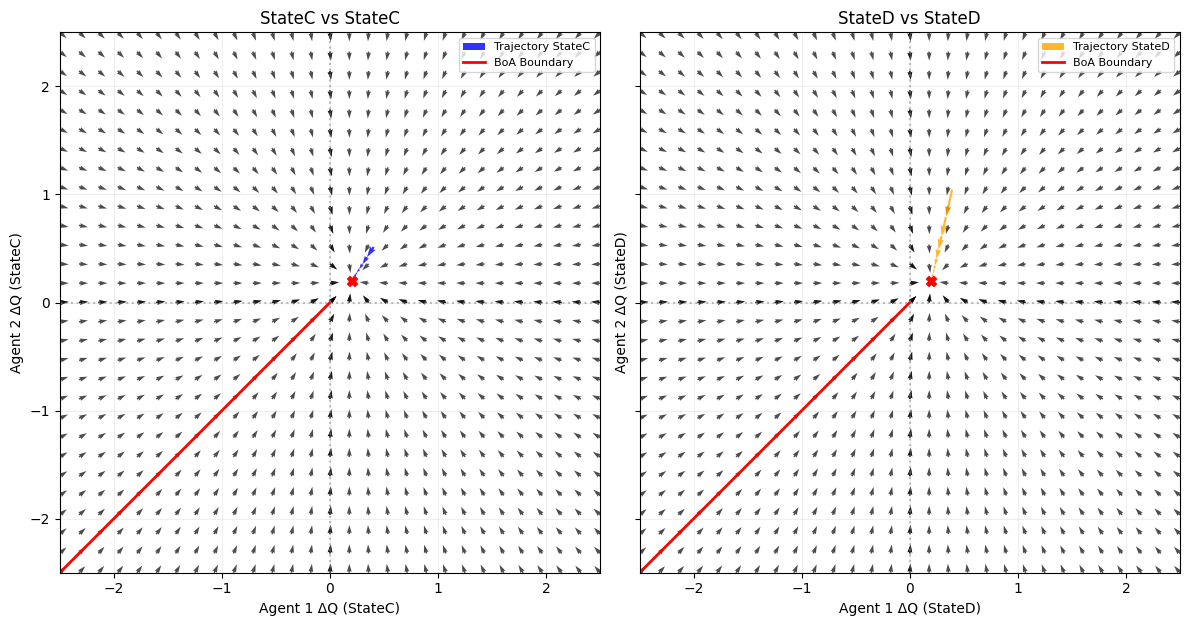

Running pair: (AD, GT)


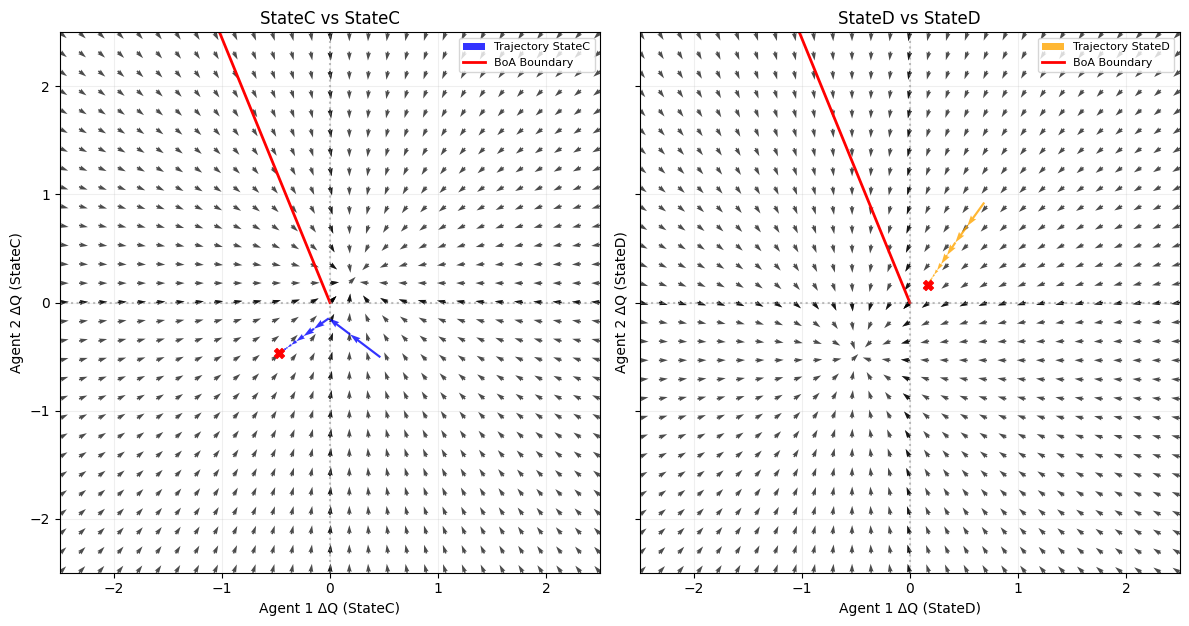

Running pair: (AD, AGT)


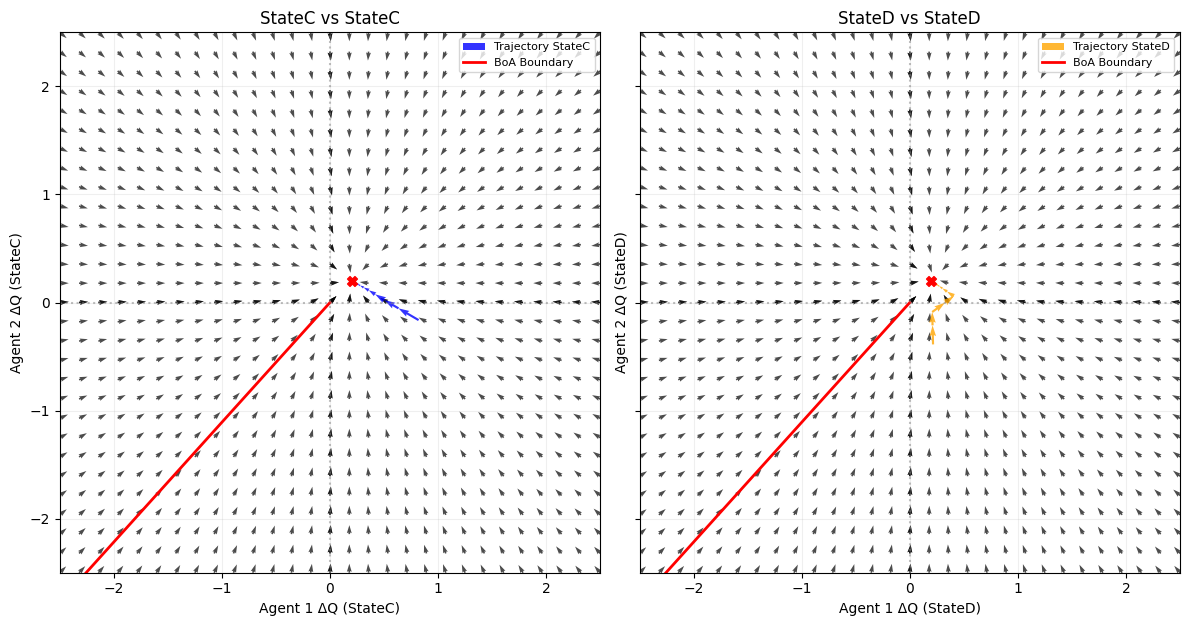

Running pair: (AD, AC)


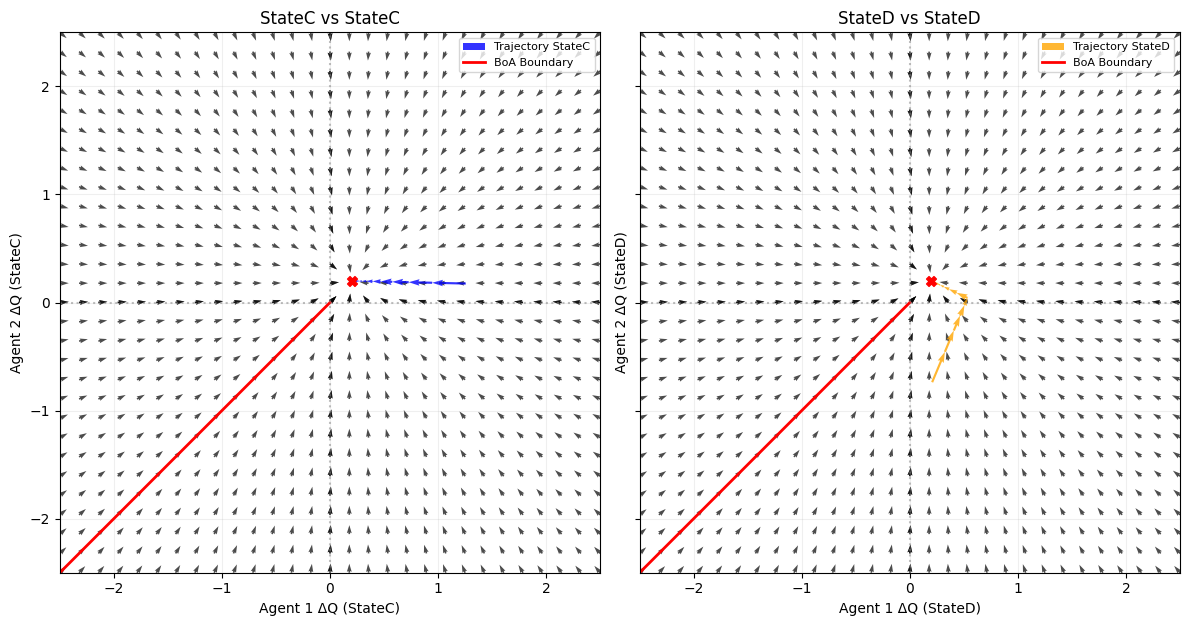

Running pair: (GT, AD)


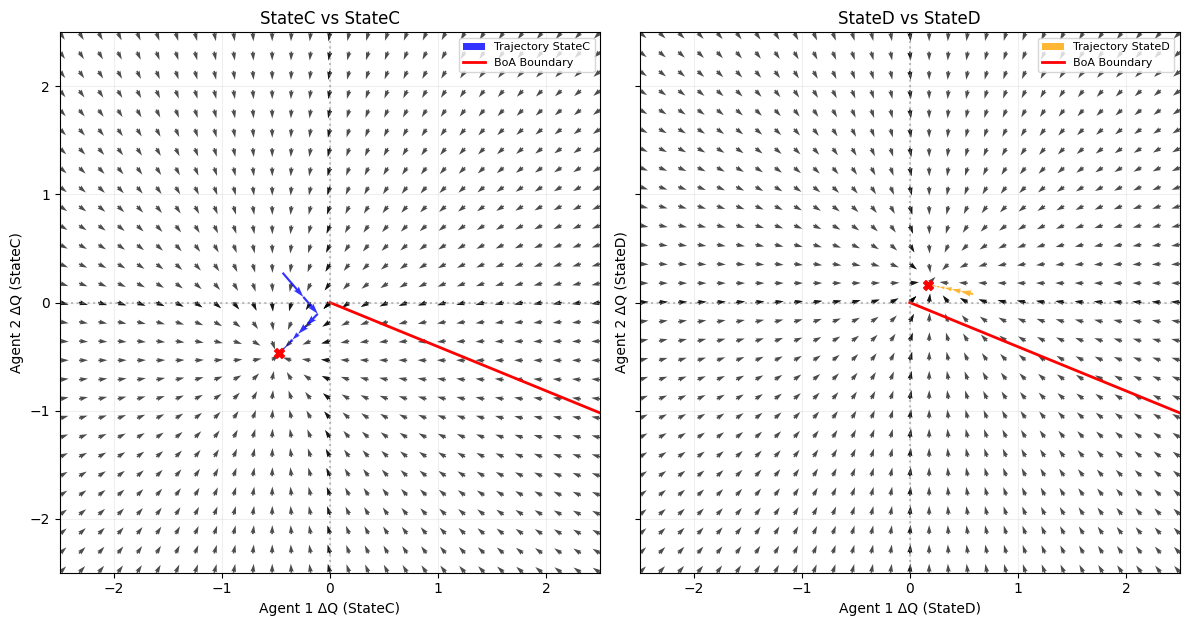

Running pair: (GT, GT)


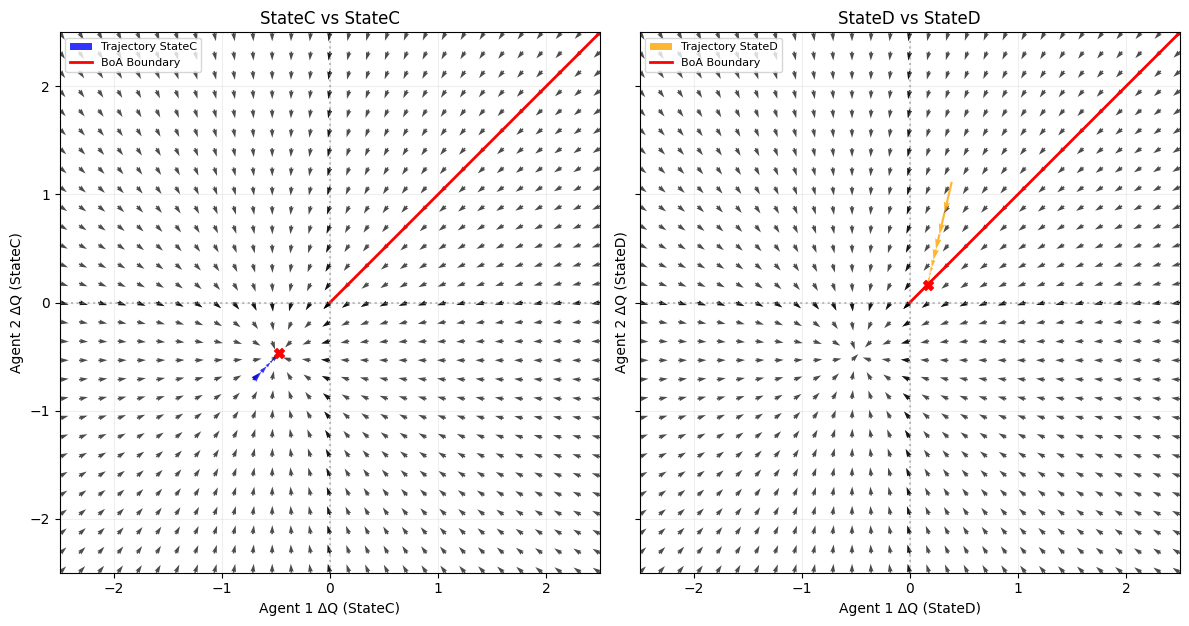

Running pair: (GT, AGT)


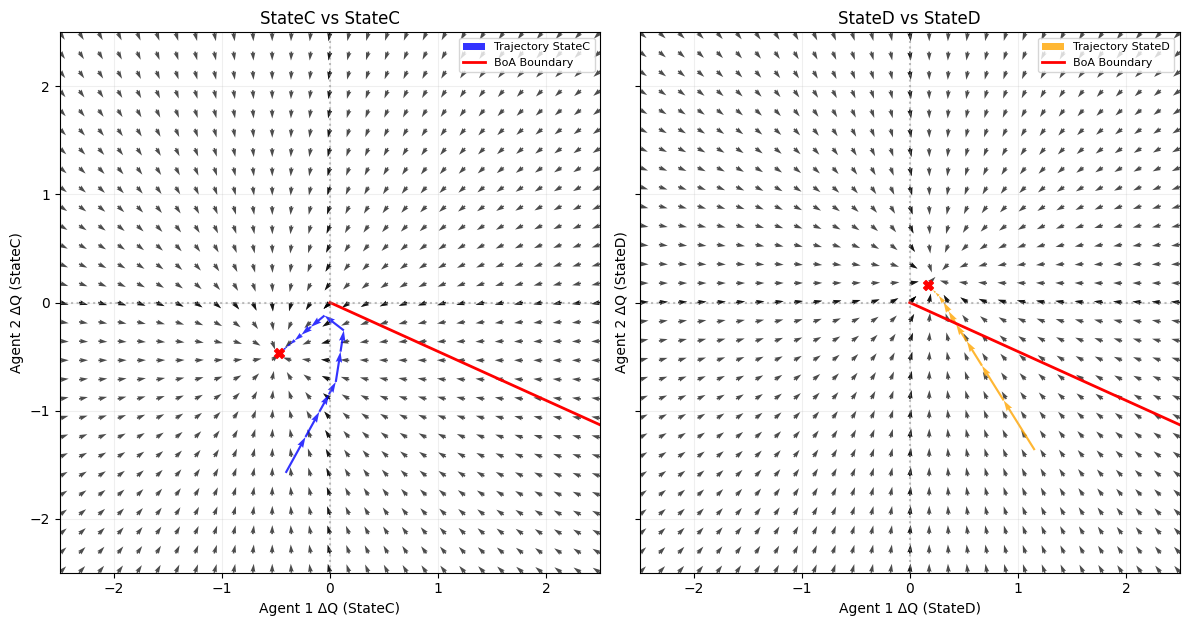

Running pair: (GT, AC)


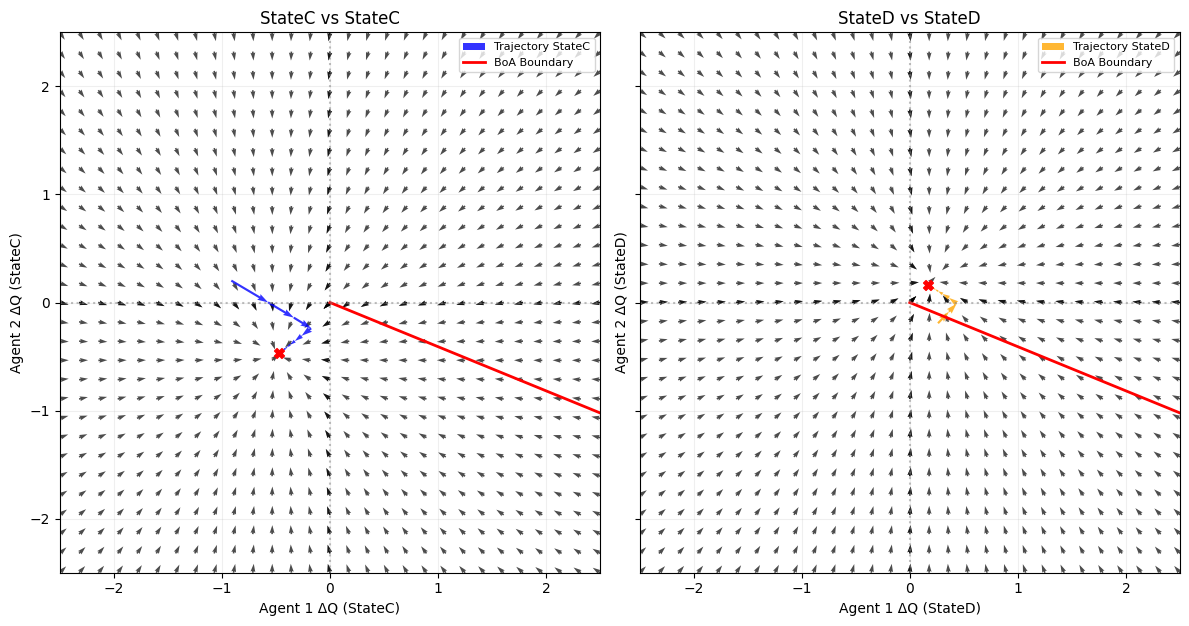

Running pair: (AGT, AD)


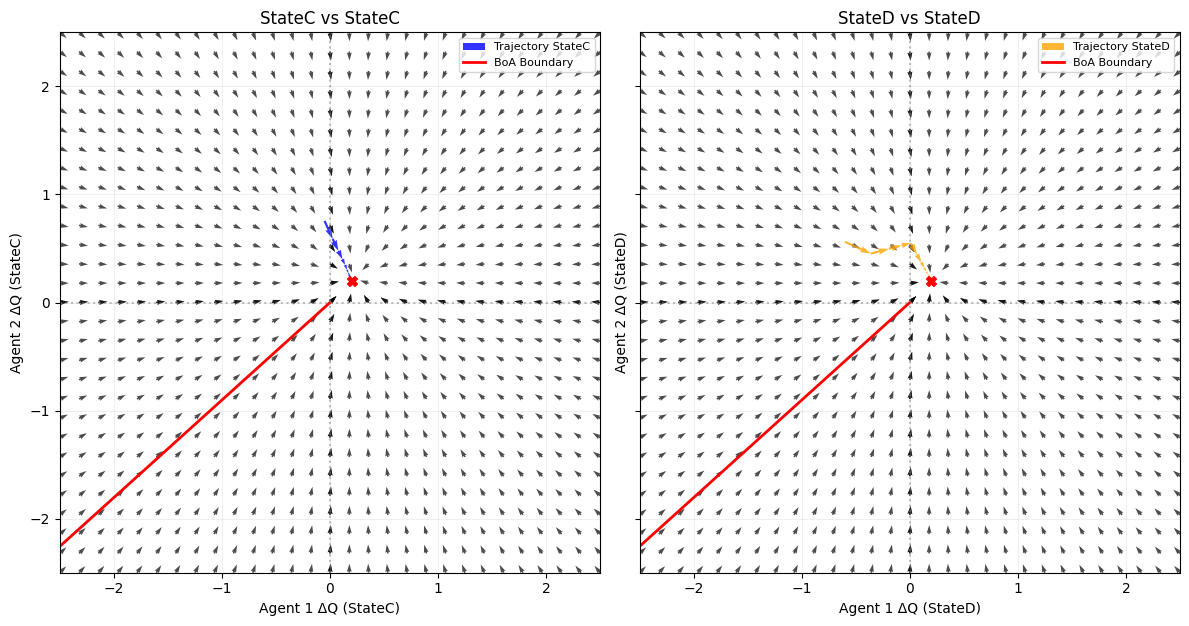

Running pair: (AGT, GT)


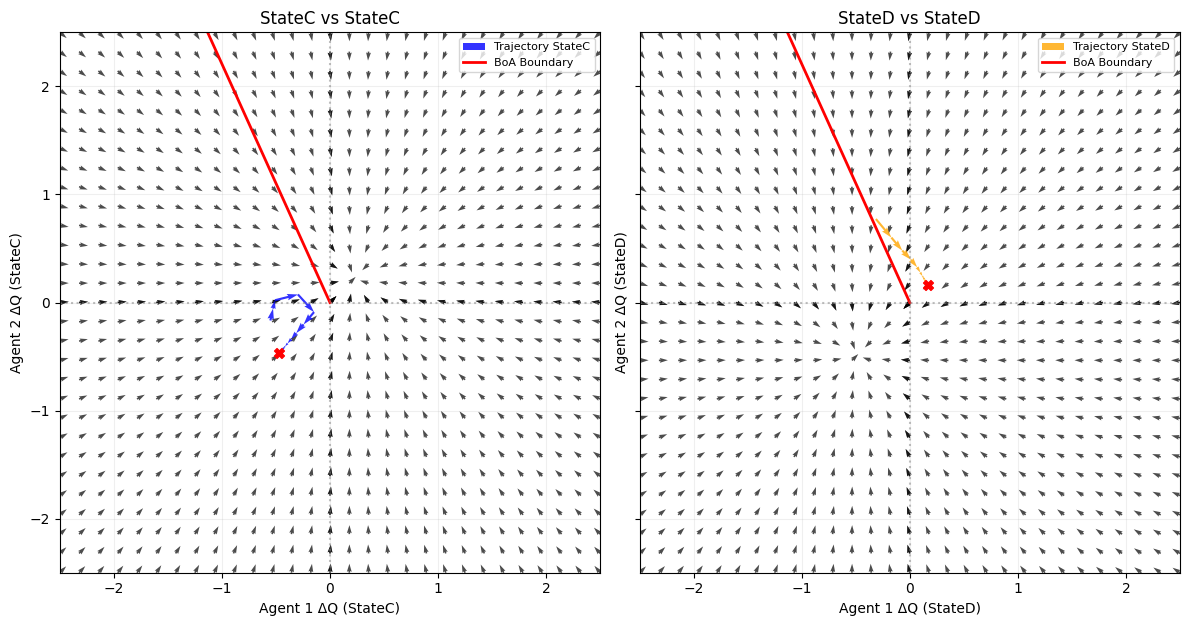

Running pair: (AGT, AGT)


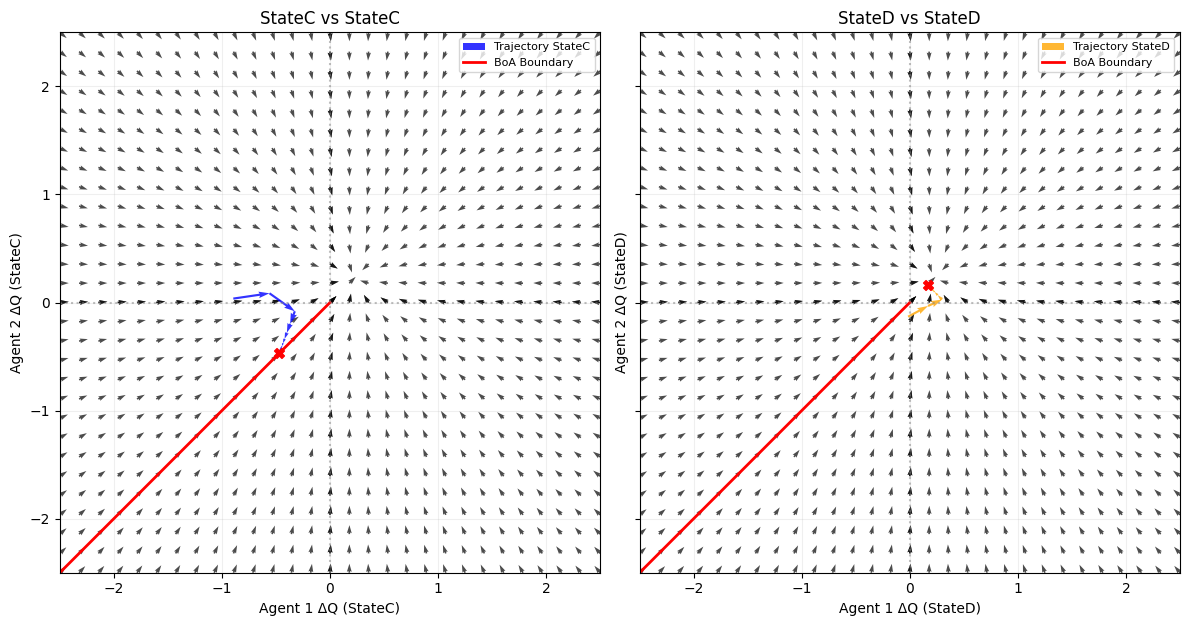

Running pair: (AGT, AC)


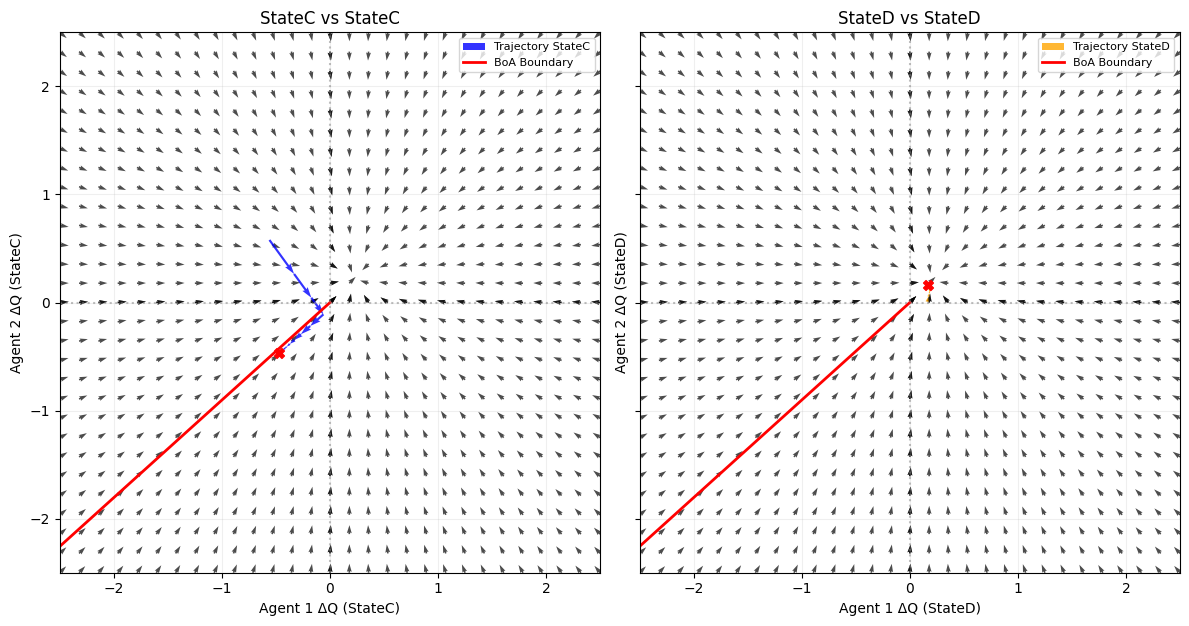

Running pair: (AC, AD)


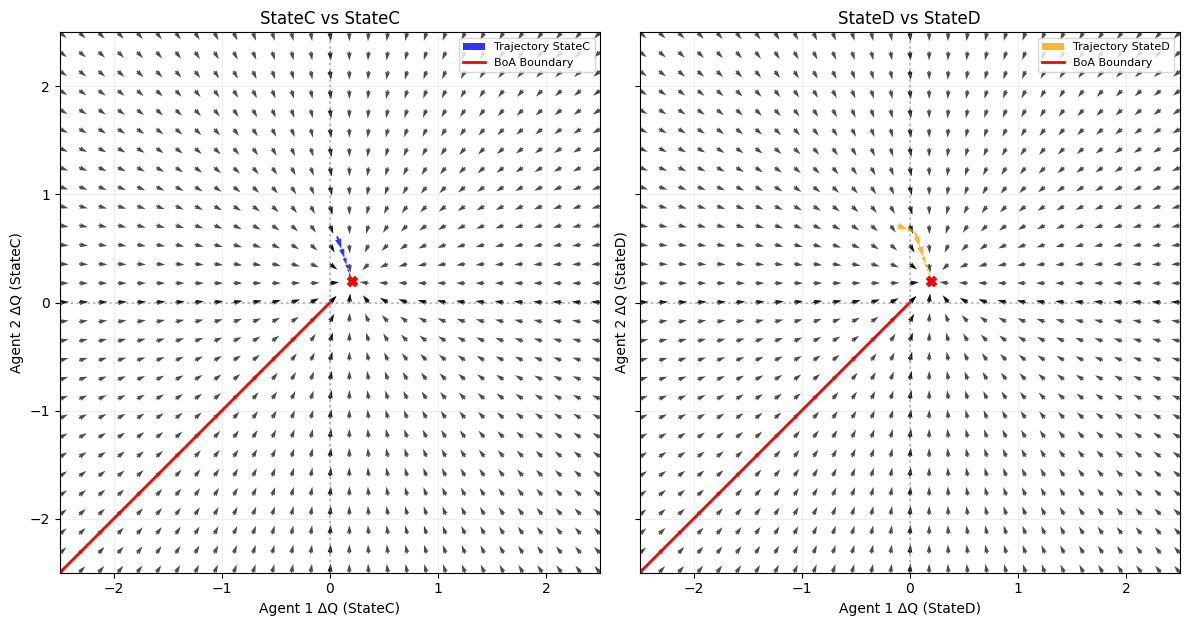

Running pair: (AC, GT)


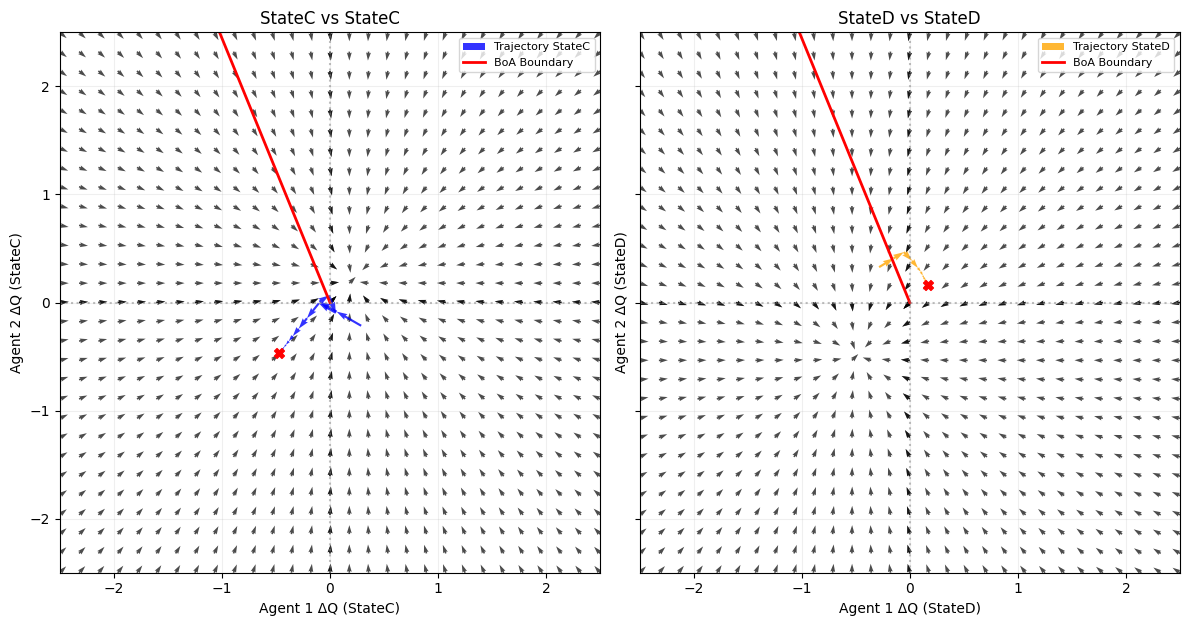

Running pair: (AC, AGT)


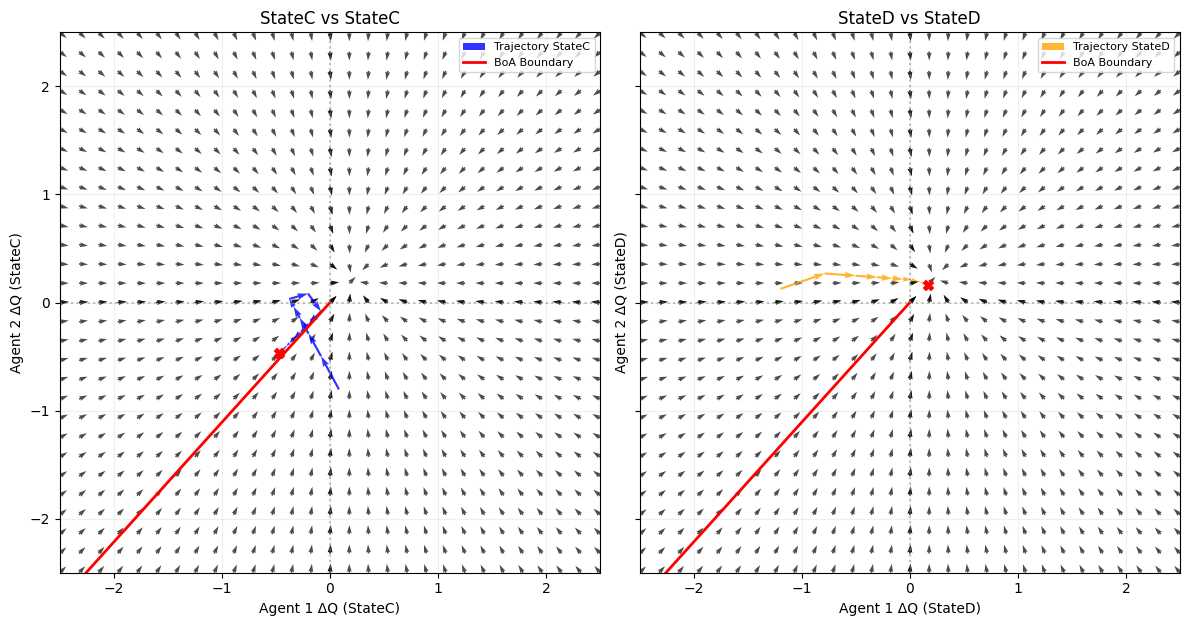

Running pair: (AC, AC)


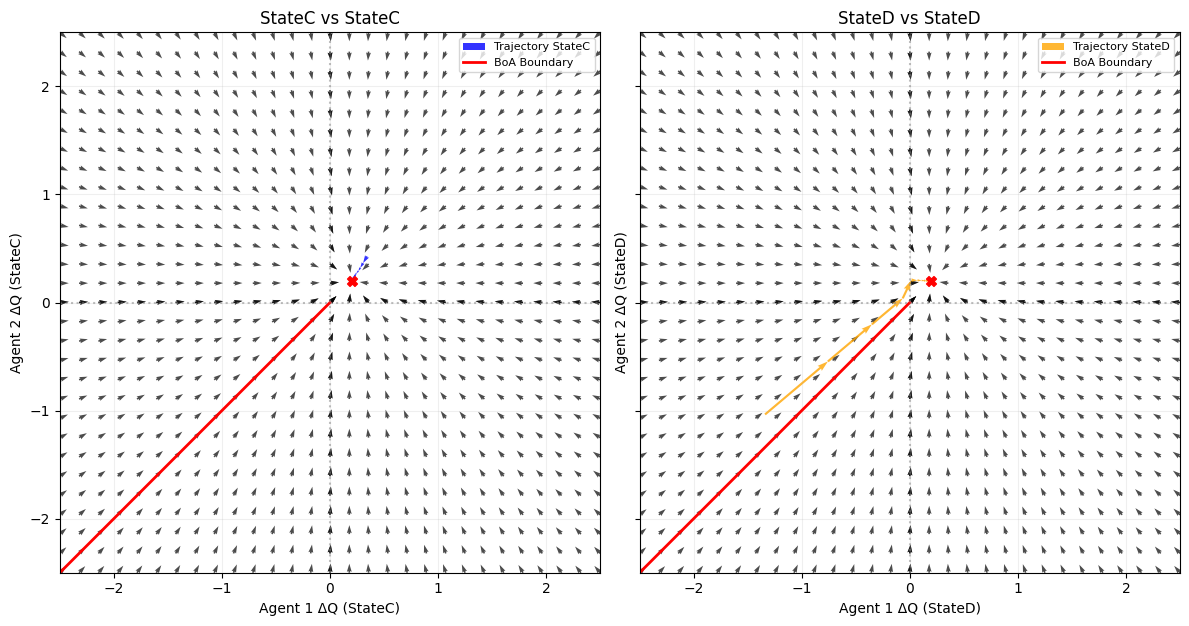

In [35]:
# Strategy pairs
strategy_pairs = [
    ("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    ("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    ("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    ("AC","AD"), ("AC","GT"), ("AC","AGT"), ("AC","AC")
]

# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}

for s1, s2 in strategy_pairs:
    print(f"Running pair: ({s1}, {s2})")

    # Initialize algorithm with fixed strategy pair
    algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=50, strategy1=s1, strategy2=s2, verbose=False
    )

    # Run the algorithm
    q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

    # Pick a sample
    exp = np.random.randint(0, 50)
    q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
    q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]

    # Select functions for vector field based on opponent strategy
    func1 = func_map[s1]  # x-component uses opponent strategy s2
    func2 = func_map[s2]  # y-component uses same opponent strategy

    # Plot vector field
    plotter = VectorFieldAutomatic(
        q1=q1, q2=q2,
        t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
        func1=func1,
        func2=func2,
        alpha=alpha,
        show_trajectory=True,
        show_basin=True
    )
    plotter.plot()
